# 02 · Exploring the Signals: what do booms and hype actually look like?

Before building any model, we look at the data with hindsight to form
hypotheses. **Nothing in this notebook is used for prediction.** It uses the
full history, including the future, on purpose. Notebooks 03–05 then test whether
these patterns could have been seen *at the time*.

Hypotheses going in:
* **H1 Diffusion lag:** real SF trends reach SEA after a measurable delay
  (infrastructure, regulation and local copycats take time).
* **H2 Synchronised hype:** media-driven hype hits SF and SEA *at the same time*,
  because news and social feeds are global, then fades in both.
* **H3 Shape:** hype is spiky and decays after the peak. Trends plateau high.
* **H4 Independence:** attention, founders, builders and research are partly
  independent signals, so seeing them *converge* carries information.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

sys.path.insert(0, str(Path.cwd().parent))
from radar.config import PROC, FIG, SECTORS, LABELLED

monthly = pd.read_parquet(PROC / "panel_monthly.parquet")
yearly = pd.read_parquet(PROC / "panel_yearly.parquet")
sectors = pd.read_parquet(PROC / "sectors.parquet")
COL = {"boom": "#2a78d6", "noise": "#eb6834", "ambiguous": "#8a8a8a", "candidate": "#2f5fb3"}

def m_series(sector, signal, smooth=6):
    s = monthly[(monthly.sector == sector) & (monthly.signal == signal)].set_index("date")["value"].sort_index()
    return s.rolling(smooth, min_periods=1).mean()

## 1 · Every labelled sector: SF vs SEA search interest
Green panels went on to boom in SEA, red panels were hype. The dashed line marks the
year the sector broke out in SEA. Each curve is scaled to its own peak, so compare
**timing and shape**, not height.

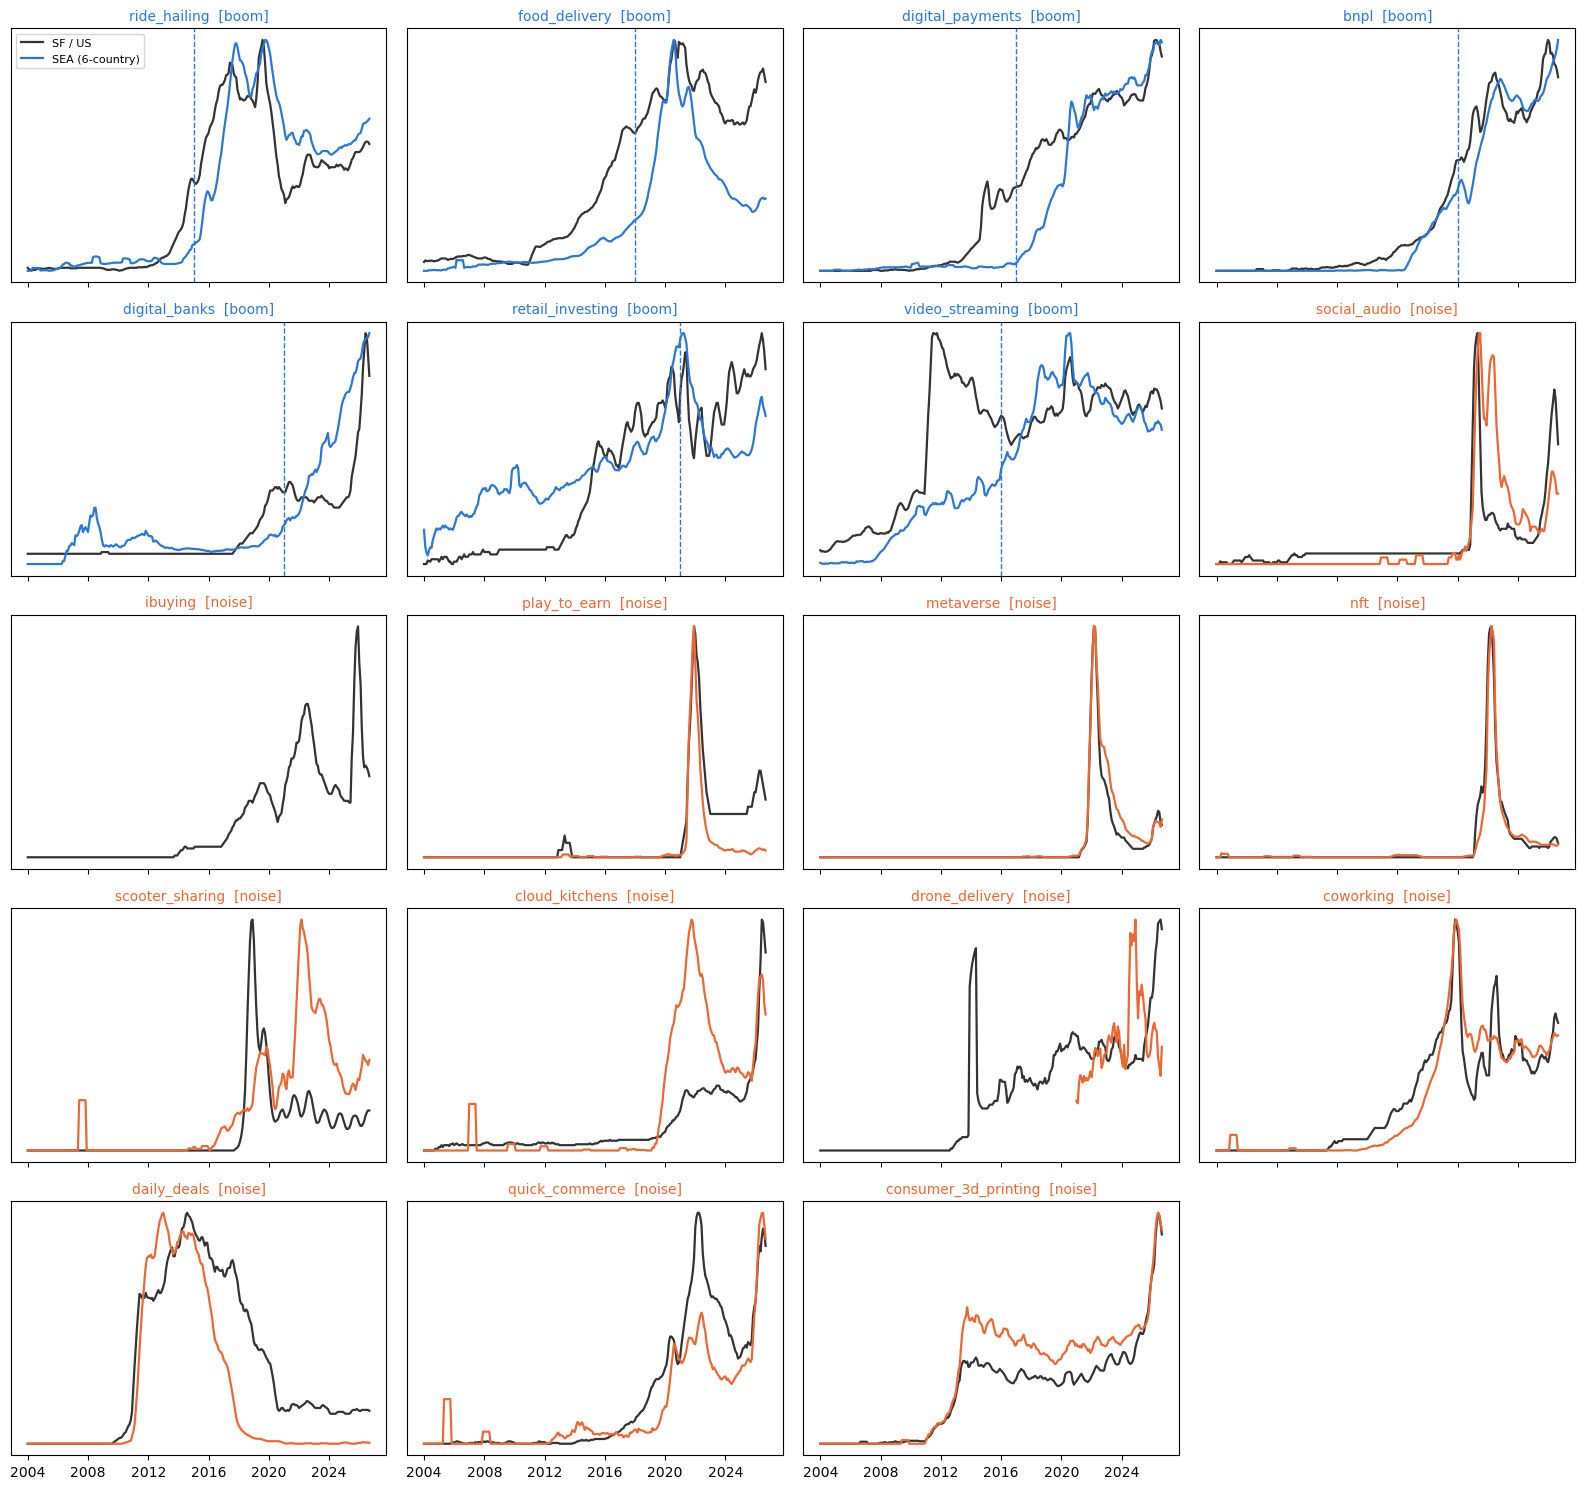

In [2]:
lab = sectors.loc[LABELLED].sort_values("label")
n = len(lab); ncol = 4; nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(16, 3 * nrow), sharex=True)
for ax, (s, row) in zip(axes.flat, lab.iterrows()):
    for sig, c, lbl in [("gt_sf", "#333333", "SF / US"), ("gt_sea", COL[row.label], "SEA (6-country)")]:
        x = m_series(s, sig)
        if len(x): ax.plot(x.index, x / x.max(), color=c, lw=1.6, label=lbl)
    if pd.notna(row.sea_boom_year): ax.axvline(pd.Timestamp(f"{int(row.sea_boom_year)}-01-01"), ls="--", color=COL["boom"], lw=1)
    ax.set_title(f"{s}  [{row.label}]", fontsize=10, color=COL[row.label])
    ax.set_yticks([])
for ax in list(axes.flat)[n:]: ax.axis("off")
axes.flat[0].legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.savefig(FIG / "02_sf_vs_sea_small_multiples.png", dpi=150); plt.show()

## 2 · H1 + H2: does SEA lag SF, and is hype synchronised?
**Onset** = the first month the 6-month-smoothed series reaches 25% of its all-time
peak. This uses hindsight, which is fine here. Points above the diagonal mean SEA
followed SF.

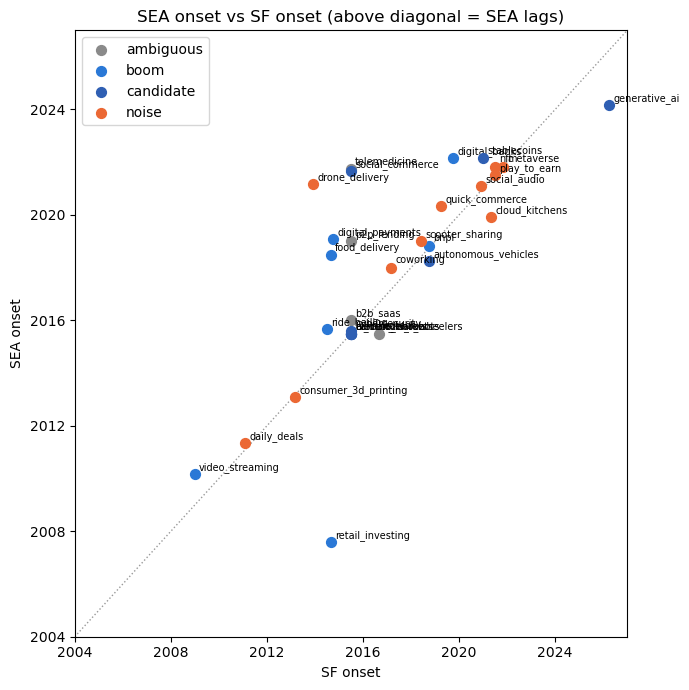

           count  mean   50%   min   max
label                                   
ambiguous    4.0  27.2  24.0 -14.0  75.0
boom         7.0  10.1  14.0 -85.0  52.0
candidate    9.0   6.4   0.0 -25.0  74.0
noise       11.0   9.8   3.0 -17.0  87.0

Mann-Whitney (boom lag > noise lag): U=54, p=0.087


In [3]:
def onset(x, frac=0.25):
    x = x.dropna()
    if len(x) == 0 or x.max() <= 0: return pd.NaT
    hit = x[x >= frac * x.max()]
    return hit.index[0] if len(hit) else pd.NaT

rows = []
for s in sectors.index:
    sf, sea = m_series(s, "gt_sf"), m_series(s, "gt_sea")
    o_sf, o_sea = onset(sf), onset(sea)
    if pd.notna(o_sf) and pd.notna(o_sea):
        rows.append(dict(sector=s, label=sectors.label[s], sf_onset=o_sf, sea_onset=o_sea,
                         lag_months=(o_sea.year - o_sf.year) * 12 + o_sea.month - o_sf.month))
lag = pd.DataFrame(rows).set_index("sector")
lag.to_parquet(PROC / "eda_onset_lags.parquet")

fig, ax = plt.subplots(figsize=(7, 7))
for l, g in lag.groupby("label"):
    ax.scatter(g.sf_onset, g.sea_onset, color=COL[l], s=50, label=l, zorder=3)
    for s, r in g.iterrows():
        ax.annotate(s, (r.sf_onset, r.sea_onset), fontsize=7, xytext=(3, 3), textcoords="offset points")
lim = [pd.Timestamp("2004-01-01"), pd.Timestamp("2027-01-01")]
ax.plot(lim, lim, color="#999", ls=":", lw=1); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("SF onset"); ax.set_ylabel("SEA onset"); ax.legend()
ax.set_title("SEA onset vs SF onset (above diagonal = SEA lags)")
plt.tight_layout(); plt.savefig(FIG / "02_onset_lag.png", dpi=150); plt.show()

summary = lag.groupby("label").lag_months.describe()[["count", "mean", "50%", "min", "max"]]
print(summary.round(1))
b, nz = lag.query("label=='boom'").lag_months, lag.query("label=='noise'").lag_months
if len(b) > 2 and len(nz) > 2:
    u = stats.mannwhitneyu(b, nz, alternative="greater")
    print(f"\nMann-Whitney (boom lag > noise lag): U={u.statistic:.0f}, p={u.pvalue:.3f}")

## 3 · H3: shape, i.e. what happens after the peak?
**Retention** = average SF interest 24–36 months after the peak, divided by the peak.
Hype should collapse and trends should hold.

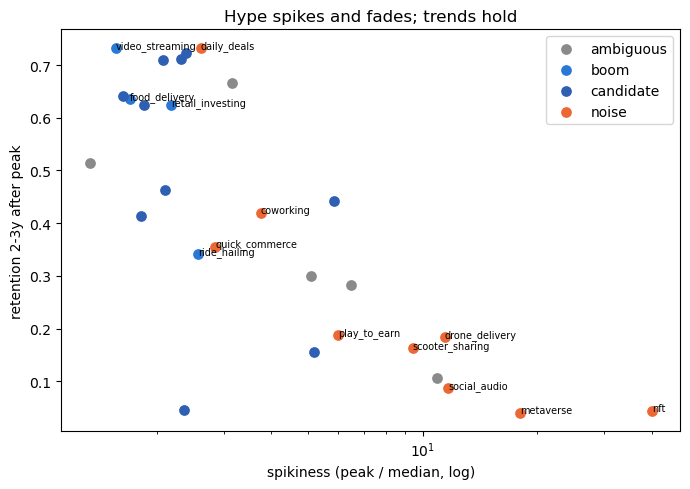

,retention,spikiness
label,,
ambiguous,0.30,5.77
boom,0.63,1.69
candidate,0.54,2.39
noise,0.18,5.91


In [4]:
def retention(x, after=(24, 36)):
    x = x.dropna()
    if len(x) < 48: return np.nan
    pk = x.idxmax(); post = x[(x.index >= pk + pd.DateOffset(months=after[0])) & (x.index <= pk + pd.DateOffset(months=after[1]))]
    return post.mean() / x.max() if len(post) else np.nan

def spikiness(x):
    x = x.dropna()
    if len(x) < 24 or x.max() <= 0: return np.nan
    x = x[x.index >= x.idxmax() - pd.DateOffset(months=36)]
    return x.max() / max(x.median(), 1e-9)

shape = pd.DataFrame({s: dict(label=sectors.label[s],
                              retention=retention(m_series(s, "gt_sf", 3)),
                              spikiness=spikiness(m_series(s, "gt_sf", 1)))
                      for s in sectors.index}).T
shape[["retention", "spikiness"]] = shape[["retention", "spikiness"]].astype(float)
fig, ax = plt.subplots(figsize=(7, 5))
for l, g in shape.groupby("label"):
    ax.scatter(g.spikiness, g.retention, color=COL[l], label=l, s=45)
    for s, r in g.iterrows():
        if l in ("boom", "noise"): ax.annotate(s, (r.spikiness, r.retention), fontsize=7)
ax.set_xscale("log"); ax.set_xlabel("spikiness (peak / median, log)"); ax.set_ylabel("retention 2-3y after peak")
ax.legend(); ax.set_title("Hype spikes and fades; trends hold")
plt.tight_layout(); plt.savefig(FIG / "02_shape.png", dpi=150); plt.show()
shape.groupby("label")[["retention", "spikiness"]].median().round(2)

## 4 · H4: are the signal families independent?
If attention, founders, builders and research all moved together, "convergence"
would just be counting one thing several times. We check the correlation of their
**year-on-year log changes** pooled across sectors.

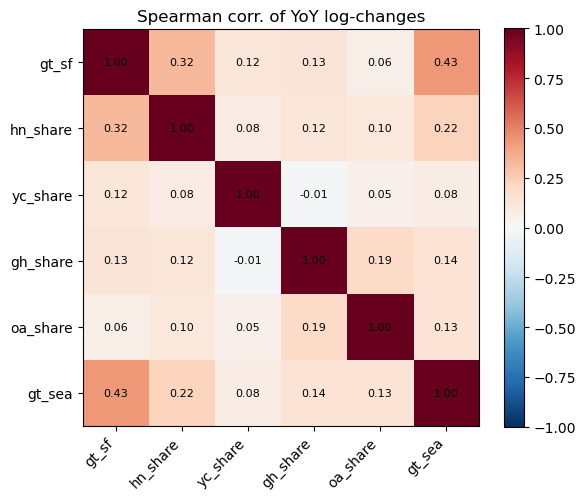

In [5]:
fam = ["gt_sf", "hn_share", "yc_share", "gh_share", "oa_share", "gt_sea"]
w = yearly[yearly.signal.isin(fam)].pivot_table(index=["sector", "year"], columns="signal", values="value")[fam]
g = np.log(w + 1e-6).groupby(level=0).diff().replace([np.inf, -np.inf], np.nan)
corr = g.corr(method="spearman", min_periods=100)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(fam)), fam, rotation=45, ha="right"); ax.set_yticks(range(len(fam)), fam)
for i in range(len(fam)):
    for j in range(len(fam)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im); ax.set_title("Spearman corr. of YoY log-changes")
plt.tight_layout(); plt.savefig(FIG / "02_signal_independence.png", dpi=150); plt.show()

## 5 · What we learned (feeds the model design)
Hindsight results across the labelled sectors:

| Hypothesis | Result | Verdict |
|---|---|---|
| **H1 diffusion lag** | Median SEA onset lag: booms **14 months**, hype **3 months** (Mann-Whitney p = 0.09) | Suggestive, not conclusive |
| **H2 synchronised hype** | Granger tests (notebook 04): hype peaks SF→SEA at **lag 0** with cross-corr 0.73. Booms peak at **~10 months** with cross-corr 0.28 | Supported |
| **H3 shape** | 2–3 yrs after peak, booms keep **63%** of peak interest and hype keeps **18%**. Hype is **3.5× spikier** | Strongly supported, but only visible *after* the peak |
| **H4 independence** | See the correlation matrix: the signal families are only weakly correlated | Supported |

**Design implication:** the most promising real-time tell is **timing**. When SEA search interest moves
in the *same month* as SF, the wave is probably media-driven. Real adoption reaches SEA months later.
Shape (H3) is decisive in hindsight but can't be seen at the moment a decision has to be made.